# Reinforcement Learning ep.0: Dynamic Programming 

***Libro consigliato:*** “Reinforcement Learning: An Introduction. Second edition.” di Richard S. Sutton e Andrew G. Barto.

**Obiettivo:** *insegnare a un taxi a prelevare e lasciare i passeggeri nei punti giusti con il Reinforcement Learning*.

## Breve riepilogo
Considera lo scenario in cui insegni nuovi trucchi a un cane. Il cane non capisce la nostra lingua, quindi non possiamo dirgli cosa fare. Seguiamo invece una strategia diversa: ricreiamo una situazione (o un segnale) e il cane prova a rispondere in molti modi diversi. Se la risposta del cane è quella desiderata, lo premiamo con uno snack. E indovina un po': la volta successiva che il cane si trova nella stessa situazione, esegue un'azione simile con ancora più entusiasmo, aspettandosi altro cibo. È come imparare "cosa fare" dalle esperienze positive. Allo stesso modo, i cani tendono a imparare cosa non fare quando affrontano esperienze negative.

Ed è esattamente così che funziona il Reinforcement Learning, in senso più ampio:

* Il tuo cane è un "agente" esposto all'**ambiente**. L'ambiente potrebbe essere casa tua, con te.
* Le situazioni che incontra sono analoghe a uno **stato**. Un esempio di stato potrebbe essere il tuo cane in piedi mentre tu, in salotto, pronunci una parola specifica con un certo tono.
* I nostri agenti reagiscono eseguendo un'**azione** per passare da uno "stato" a un altro "stato": il tuo cane, per esempio, passa da in piedi a seduto.
* Dopo la transizione, possono ricevere in cambio una **ricompensa** o una **penalità**. Gli dai un premio! Oppure un "No" come penalità.
* La **policy** è la strategia con cui si sceglie un'azione dato uno stato, in attesa di risultati migliori.


Il Reinforcement Learning si colloca tra il Supervised Learning e l'Unsupervised Learning, e ci sono alcune cose importanti da notare:

1. **Essere greedy non funziona sempre**  
Ci sono cose facili da fare per una gratificazione immediata, e cose che portano ricompense a lungo termine. L'obiettivo non è essere greedy cercando le ricompense rapide e immediate, ma ottimizzare per ottenere la ricompensa massima sull'intero addestramento.  
2. **Nel Reinforcement Learning la sequenza conta**  
La ricompensa dell'agente non dipende solo dallo stato corrente, ma dall'intera storia degli stati. A differenza del supervised e dell'unsupervised learning, qui il tempo è importante.

### Il processo
In un certo senso, il Reinforcement Learning è la scienza del prendere decisioni ottimali usando l'esperienza. Scomponendolo, il processo del Reinforcement Learning prevede questi semplici passi:

1. Osservare l'ambiente
2. Decidere come agire usando una certa strategia
3. Agire di conseguenza
4. Ricevere una ricompensa o una penalità
5. Imparare dalle esperienze e affinare la strategia
6. Ripetere finché non si trova una strategia ottima


![alt](https://storage.googleapis.com/lds-media/documents/Reinforcement-Learning-Animation.gif)


## Taxi a guida autonoma

Progettiamo una simulazione di un taxi a guida autonoma. Lo scopo principale è mostrare, in un ambiente semplificato, come si possono usare le tecniche di RL per sviluppare un approccio efficiente e sicuro a questo problema.

Il compito dello Smartcab è prelevare il passeggero in un punto e lasciarlo in un altro. Ecco alcune cose di cui vorremmo che il nostro Smartcab si occupasse:

* Lasciare il passeggero nel punto giusto.
* Far risparmiare tempo al passeggero, impiegando il minor tempo possibile per la consegna.
* Tenere conto della sicurezza del passeggero e delle regole del traffico.


Ci sono diversi aspetti da considerare quando si modella una soluzione di RL per questo problema: ricompense, stati e azioni.

#### Ricompense

Poiché l'agente (il guidatore immaginario) è motivato dalle ricompense e imparerà a guidare il taxi per tentativi nell'ambiente, dobbiamo decidere di conseguenza le ricompense e/o le penalità e la loro entità. Ecco alcuni punti da considerare:

* L'agente dovrebbe ricevere una ricompensa positiva alta per una consegna riuscita, perché questo comportamento è molto desiderato
* L'agente dovrebbe essere penalizzato se prova a lasciare un passeggero nel punto sbagliato
* L'agente dovrebbe ricevere una piccola ricompensa negativa per ogni time-step in cui non ha ancora raggiunto la destinazione. "Piccola" perché preferiamo che il nostro agente arrivi in ritardo piuttosto che faccia mosse sbagliate cercando di arrivare a destinazione il più in fretta possibile

#### Spazio degli stati
Nel Reinforcement Learning, l'agente incontra uno stato e poi esegue un'azione in base allo stato in cui si trova.

Lo spazio degli stati è l'insieme di tutte le situazioni possibili in cui il nostro taxi può trovarsi. Lo stato dovrebbe contenere le informazioni utili di cui l'agente ha bisogno per scegliere l'azione giusta.

Supponiamo di avere un'area di addestramento per il nostro Smartcab, in cui gli insegniamo a trasportare persone in un parcheggio verso quattro punti diversi (R, G, Y, B):

![alt](https://storage.googleapis.com/lds-media/images/Reinforcement_Learning_Taxi_Env.width-1200.png)

Supponiamo che lo Smartcab sia l'unico veicolo in questo parcheggio. Possiamo suddividere il parcheggio in una griglia $5x5$, che ci dà $25$ possibili posizioni del taxi. Queste $25$ posizioni sono una parte del nostro spazio degli stati. Nota che la posizione corrente del nostro taxi è la coordinata $(3, 1)$.

Noterai anche che ci sono 4 punti in cui possiamo prelevare e lasciare un passeggero: R, G, Y, B, cioè $[(0,0), (0,4), (4,0), (4,3)]$ in coordinate (riga, colonna). Il passeggero dell'illustrazione si trova nel punto Y e vuole andare nel punto R.

Se teniamo conto anche di uno stato aggiuntivo del passeggero, cioè quello in cui si trova dentro il taxi, possiamo considerare tutte le combinazioni di posizioni del passeggero e di destinazioni per arrivare al numero totale di stati del nostro ambiente taxi: ci sono $4$ destinazioni e cinque $(4 + 1)$ posizioni del passeggero.

Quindi il nostro ambiente taxi ha in totale $5\times5\times5\times4 = 500$ stati possibili.

#### Spazio delle azioni

L'agente incontra uno dei 500 stati ed esegue un'azione. Nel nostro caso l'azione può essere muoversi in una direzione oppure decidere di prelevare/lasciare un passeggero.

In altre parole, abbiamo sei azioni possibili:

1. Sud
2. Nord
3. Est
4. Ovest
5. Pickup
6. Dropoff

Questo è lo spazio delle azioni: l'insieme di tutte le azioni che il nostro agente può eseguire in un dato stato.

Noterai nell'illustrazione qui sopra che il taxi non può eseguire certe azioni in certi stati a causa dei muri. Nel codice dell'ambiente daremo semplicemente una penalità di $-1$ per ogni urto contro un muro, e il taxi non si muoverà. Questo farà solo accumulare penalità, spingendo il taxi a considerare di aggirare il muro.


### Implementazione

Per fortuna, [OpenAI Gymnasium](https://gymnasium.farama.org) ha già questo esatto ambiente pronto per noi.

Gym fornisce diversi ambienti di gioco che possiamo collegare al nostro codice per testare un agente. La libreria si occupa dell'API che fornisce tutte le informazioni di cui il nostro agente ha bisogno, come le azioni possibili, il punteggio e lo stato corrente. Dobbiamo concentrarci solo sulla parte algoritmica del nostro agente.

Useremo l'ambiente Gym chiamato [Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/), da cui sono stati presi tutti i dettagli spiegati sopra. Gli obiettivi, le ricompense e le azioni sono gli stessi.

Per prima cosa dobbiamo installare `gymnasium`. Poi possiamo caricare l'ambiente di gioco e visualizzare com'è fatto.

In [29]:
# Installo i pacchetti necessari nel kernel del notebook corrente
%pip install gymnasium
%pip install pygame
%pip install matplotlib
%pip install numpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
# Importo le librerie necessarie
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import animation
from IPython import display
from IPython.display import clear_output
from time import sleep
import random

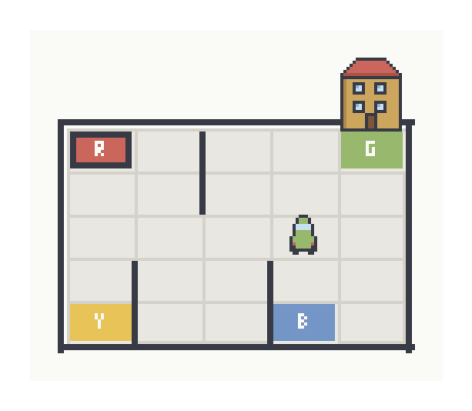

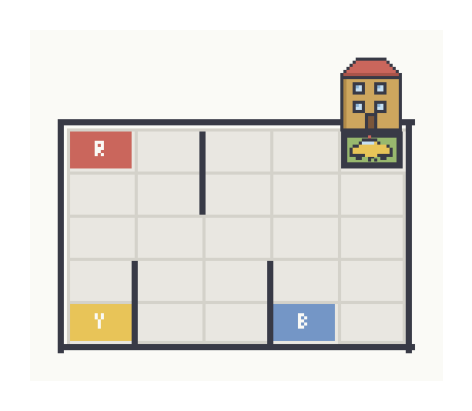

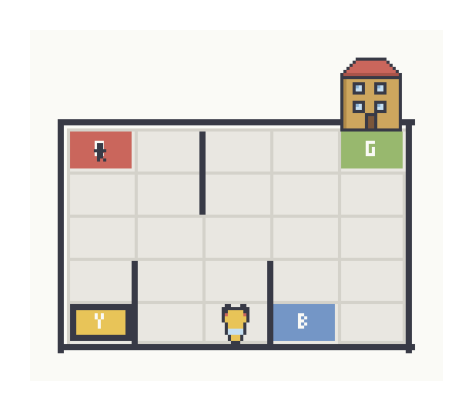

In [31]:
# 1. Creo l'ambiente Taxi, con render come array RGB
env = gym.make('Taxi-v4',render_mode = "rgb_array").env

# 2. Resetto l'ambiente e disegno il frame iniziale
env.reset()
img = env.render()
_ = plt.imshow(img)
plt.show()

In [32]:
# Leggo lo stato corrente (un intero tra 0 e 499)
state = env.unwrapped.s
print(state)

442


In [33]:
# 1. Decodifico lo stato nelle sue componenti
decoded_state = env.unwrapped.decode(state)
taxi_row, taxi_col, passenger_loc, destination = decoded_state

# 2. Stampo le singole componenti
print(f"Stato decodificato = {decoded_state}")
print("Posizione del taxi:", taxi_row, taxi_col)
print("Posizione del passeggero:", passenger_loc)
print("Destinazione:", destination)

Stato decodificato = (np.int64(4), np.int64(2), np.int64(0), np.int64(2))
Posizione del taxi: 4 2
Posizione del passeggero: 0
Destinazione: 2


### Il dizionario delle transizioni di stato (`env.P`)

In Taxi-v3 di Gymnasium, il dizionario `env.P[state]` definisce la dinamica dell'**MDP (Processo Decisionale di Markov)** dell'ambiente per uno stato specifico. Ogni chiave rappresenta una delle sei azioni possibili (0–5), e il valore corrispondente è una lista di tuple nel formato `(probability, next_state, reward, done)`. Poiché Taxi-v3 è un ambiente deterministico, la **probabilità** (`probability`) vale sempre `1.0`. Il **next_state** è l'ID intero dello stato risultante, la **reward** è il feedback numerico (tipicamente `-1` per i movimenti e `-10` per le azioni illegali), e **done** è un booleano che indica se l'episodio termina (ad es. dopo una consegna riuscita).


In [34]:
# Dizionario delle transizioni dallo stato corrente: {azione: [(probabilità, stato successivo, ricompensa, done)]}
action = env.env.unwrapped.P[state]

In [35]:
action

{0: [(1.0, 442, -1, False)],
 1: [(1.0, 342, -1, False)],
 2: [(1.0, 442, -1, False)],
 3: [(1.0, 422, -1, False)],
 4: [(1.0, 442, -10, False)],
 5: [(1.0, 442, -10, False)]}

In [36]:
# Eseguo l'azione 0 (sud)
observation, reward, terminated, truncated, info = env.step(0)

In [37]:
# Leggo il nuovo stato dopo l'azione
state = env.unwrapped.s
print(state)

442


L'interfaccia principale di gym è `env`, l'interfaccia unificata dell'ambiente. Questi sono i metodi di `env` che ci saranno più utili:

* `env.reset`: resetta l'ambiente e restituisce uno stato iniziale casuale.
* `env.step(action)`: fa avanzare l'ambiente di un time-step. Restituisce
  - **observation**: le osservazioni dell'ambiente
  - **reward**: se la tua azione è stata vantaggiosa o no
  - **done**: indica se abbiamo prelevato e lasciato con successo un passeggero, cioè se si è concluso un episodio
  - **truncated**: indica se è soddisfatta una condizione di troncamento esterna all'MDP. Tipicamente è un limite di tempo, ma può anche indicare che un agente è uscito fisicamente dai limiti
  - **info**: informazioni aggiuntive, che contengono la probabilità con cui viene raggiunto lo stato e una maschera delle azioni che portano a un cambio di stato, per velocizzare l'addestramento
* `env.render`: renderizza un frame dell'ambiente (utile per visualizzarlo)

*Nota*: usiamo `.env` alla fine di make per evitare che l'addestramento si fermi a 200 iterazioni, che è il default nella nuova versione di Gym.

Ecco la definizione del problema riformulata (dalla documentazione di Gym):

> Ci sono 4 punti (indicati da lettere diverse), e il nostro compito è prelevare il passeggero in un punto e lasciarlo in un altro. Riceviamo +20 punti per una consegna riuscita e perdiamo 1 punto per ogni time-step impiegato. C'è anche una penalità di 10 punti per le azioni illegali di pick-up e drop-off.

Approfondiamo l'ambiente.

In [38]:
print("Spazio delle azioni: {}".format(env.action_space))
print("Spazio degli stati: {}".format(env.observation_space))

Spazio delle azioni: Discrete(6)
Spazio degli stati: Discrete(500)


Come confermano le stampe, abbiamo uno spazio delle azioni di dimensione $6$ e uno spazio degli stati di dimensione $500$. Come vedrai, il nostro algoritmo di RL non avrà bisogno di altre informazioni oltre a queste due. Ci serve solo un modo per identificare univocamente uno stato, assegnando un numero unico a ogni stato possibile, e il RL impara a scegliere un numero di azione da 0 a 5, dove:

- 0 = sud
- 1 = nord
- 2 = est
- 3 = ovest
- 4 = pickup
- 5 = dropoff

Ricorda che i $500$ stati corrispondono a una codifica della posizione del taxi, della posizione del passeggero e della destinazione.

Il Reinforcement Learning imparerà una mappatura dagli **stati** all'**azione** ottima da eseguire in quello stato tramite *esplorazione*, cioè l'agente esplora l'ambiente ed esegue azioni in base alle ricompense definite nell'ambiente.

L'azione ottima per ogni stato è quella con la *ricompensa cumulativa a lungo termine più alta*.

Quando l'ambiente Taxi viene creato, viene creata anche una tabella iniziale delle ricompense, chiamata `P`. Possiamo pensarla come una matrice che ha il numero di stati come righe e il numero di azioni come colonne, cioè una matrice $stati \times azioni$.

Poiché ogni stato è in questa matrice, possiamo vedere i valori di ricompensa di default assegnati allo stato della nostra illustrazione. L'output è un dizionario con la struttura `{action: [(probability, nextstate, reward, done)]}`.

In [39]:
current_state = env.env.unwrapped.s
print("Stato corrente: {}".format(current_state))

Stato corrente: 442


In [40]:
# Transizioni dell'azione 1 (nord) dallo stato corrente
env.unwrapped.P[current_state][1]

[(1.0, 342, -1, False)]

Alcune cose da notare:

- Lo 0-5 corrisponde alle azioni (sud, nord, est, ovest, pickup, dropoff) che il taxi può eseguire nello stato corrente dell'illustrazione.
- In questo env, `probability` vale sempre 1.0.
- `nextstate` è lo stato in cui ci troveremmo eseguendo l'azione corrispondente a questo indice del dizionario
- In questo particolare stato, tutte le azioni di movimento hanno ricompensa -1 e le azioni pickup/dropoff hanno ricompensa -10. Se fossimo in uno stato in cui il taxi ha un passeggero a bordo e si trova sopra la destinazione giusta, vedremmo una ricompensa di 20 per l'azione di dropoff (5)
- `done` serve a dirci quando abbiamo lasciato con successo un passeggero nel punto giusto. Ogni consegna riuscita segna la fine di un episodio 

Il codice sorgente rende impossibile muovere davvero il taxi attraverso un muro, quindi se il taxi sceglie quell'azione continuerà semplicemente ad accumulare penalità di $-1$, il che influisce sulla ricompensa a lungo termine.

### Risolvere l'ambiente senza RL
Vediamo cosa succederebbe se provassimo a risolvere il problema con la forza bruta, senza RL.

Poiché abbiamo la nostra tabella `P` con le ricompense di default in ogni stato, possiamo provare a far navigare il taxi usando solo quella.

Creeremo un ciclo infinito che gira finché un passeggero non raggiunge una destinazione (un episodio), o in altre parole, finché la ricompensa ricevuta non è $20$. Il metodo `env.action_space.sample()` seleziona automaticamente un'azione casuale dall'insieme di tutte le azioni possibili.

Vediamo cosa succede:

In [41]:
# 1. Inizializzo contatori e variabili dell'episodio
epochs = 0
penalties, reward = 0, 0

frames = [] # per l'animazione

done = False
maxepochs = 1000
cumulative_reward = 0

while not done:
    # 2. Scelgo un'azione casuale e la eseguo
    action = env.action_space.sample()
    state, reward, done, truncated, info = env.step(action)

    # 3. Conto le penalità (pickup/dropoff illegali)
    if reward == -10:
        penalties += 1

    cumulative_reward += reward
    
    # 4. Salvo ogni frame renderizzato in un dizionario per l'animazione
    frames.append({
        'frame': env.render(),
        'state': state,
        'action': action,
        'reward': reward
        }
    )

    epochs += 1

    # 5. Mi fermo in caso di troncamento o se supero il numero massimo di passi
    if truncated:
      break 
    if epochs == maxepochs:
      break
    

print("Terminato: {}".format(done))
print("Passi effettuati: {}".format(epochs))
print("Penalità ricevute: {}".format(penalties))
print("Ricompensa cumulativa: {}".format(cumulative_reward))

Terminato: False
Passi effettuati: 1000
Penalità ricevute: 313
Ricompensa cumulativa: -3817


In [42]:
# deprecata, molto lenta e disordinata
def print_frames(frames):
    """Mostro i frame uno alla volta, con stato, azione e ricompensa."""
    for i, frame in enumerate(frames):
        clear_output(wait=True)
        plt.imshow(frame['frame'])
        plt.title(f"Passo: {i + 1}")
        plt.axis("off")
        plt.show()

        print(f"Passo: {i + 1}")
        print(f"Stato: {frame['state']}")
        print(f"Azione: {frame['action']}")
        print(f"Ricompensa: {frame['reward']}")
        plt.pause(0.2)
        sleep(0.2)


# usa questa per visualizzare cosa sta succedendo
def display_animation(frames):
  """Converto la lista di frame in un video HTML da mostrare nel notebook."""
  # 1. Disattivo la visualizzazione interattiva di matplotlib nel notebook
  plt.ioff()

  fps = 5   # Frame al secondo
  dpi = 300  # Punti per pollice
  interval = 100  # Intervallo tra i frame (in ms)

  # 2. Recupero i frame dal buffer delle esperienze
  allframes = []
  for frame in frames:
      allframes.append(frame['frame'])

  # 3. Fisso la dimensione della figura
  plt.figure(figsize=(allframes[0].shape[1] / dpi, allframes[0].shape[0] / dpi), dpi=dpi)
  patch = plt.imshow(allframes[0])
  plt.axis('off')

  # 4. Genero l'animazione
  def animate(i):
      patch.set_data(allframes[i])

  anim = animation.FuncAnimation(plt.gcf(), animate, frames=len(allframes), interval=interval)

  # 5. La converto in video HTML
  video = anim.to_html5_video()
  html = display.HTML(video)
  return html

In [43]:
# Creo e mostro l'animazione dell'episodio casuale
html = display_animation(frames)
display.display(html)

Se il rendering non funziona, installa ffmpeg.

Non va bene. Il nostro agente impiega migliaia di time-step (se glielo lasciamo fare) e fa molte consegne sbagliate per portare un solo passeggero alla destinazione giusta.

Questo perché non stiamo imparando dall'esperienza passata. Possiamo eseguirlo più e più volte, e non migliorerà mai. L'agente non ha memoria di quale azione sia stata la migliore per ogni stato, ed è esattamente ciò che il Reinforcement Learning farà per noi.

## Policy Iteration

Un modo comune per risolvere i problemi MDP è l'algoritmo di Policy Iteration. Applica iterativamente la policy evaluation e la policy improvement fino alla convergenza. 

Per chiarire:

- Policy evaluation: calcolare la funzione di valore degli stati $v_\pi (s)$ per la policy corrente $\pi$ e $\forall s \in \mathcal{S}$; questo è chiamato anche 'prediction problem' (problema di predizione)
- Policy improvement: migliorare la policy aggiornando le azioni raccomandate dalla funzione azione-valore $q_\pi (s, a)$, derivata dalla funzione di valore degli stati calcolata al passo precedente.

Il problema di predizione si può risolvere usando l'equazione di Bellman:

\begin{equation}
    v_\pi (s) = \mathbb{E}_\pi [r_{t+1} + \gamma v_\pi (s_{t + 1}) | s_t = s] = \sum_a \pi (a|s) \sum_{s', a'} p(s', r | s, a) [r + \gamma v(s')]
\end{equation}

dove:

- r è la ricompensa ottenuta eseguendo l'azione a dallo stato s. In molti libri è indicata come r(s, a) o anche r(s', a, s), per specificare lo stato di partenza, l'azione e il nuovo stato.
- $\gamma \in$ [0,1] è il fattore di sconto (o tasso di sconto) e determina il valore presente delle ricompense future.
- p(s', r | s, a) è la probabilità di transizione

La funzione azione-valore nel passo di policy improvement si può calcolare nel modo seguente:

\begin{equation}
    q_\pi (s,a) = \sum_{s'} p(s', r | s, a)[r + \gamma v_\pi (s')]
\end{equation}

In particolare, cerchiamo le azioni che massimizzano la funzione azione-valore, quindi la policy migliorata si calcola come segue:

\begin{equation}
    \pi ' (s) = \textit{argmax}_a q_\pi (s, a)
\end{equation}

L'algoritmo completo è mostrato qui: 

![Alt text](https://3.bp.blogspot.com/-MgVsC80Z8tw/Xx8uR7rM_TI/AAAAAAAAJoo/FUDT7k58a4IkdHYojUD_BU5elxx_eYucgCLcBGAsYHQ/s1600/policy_iteration_2.png "a title")

#### ***1. Scrivi il codice per la policy iteration***

In [44]:
#TODO

def q_from_v(P, V, s, n_actions, gamma):
    """Calcolo q(s, a) = sum_s' p * (r + gamma * V(s')) per tutte le azioni dello stato s."""
    q = np.zeros(n_actions)
    for a in range(n_actions):
        for prob, next_state, reward, done in P[s][a]:
            # Se la transizione termina l'episodio, dopo non c'è più valore futuro
            q[a] += prob * (reward + gamma * V[next_state] * (not done))
    return q


def policy_evaluation(P, policy, n_states, gamma=0.99, theta=1e-8):
    """Calcolo V_pi applicando l'equazione di Bellman finché i valori non si stabilizzano."""
    # 1. Parto da V = 0 per tutti gli stati
    V = np.zeros(n_states)
    while True:
        delta = 0
        for s in range(n_states):
            v_old = V[s]
            # 2. Aggiorno V(s) seguendo l'azione scelta dalla policy
            a = policy[s]
            V[s] = sum(prob * (reward + gamma * V[next_state] * (not done))
                       for prob, next_state, reward, done in P[s][a])
            # 3. Tengo traccia della variazione più grande
            delta = max(delta, abs(v_old - V[s]))
        # 4. Mi fermo quando nessun valore cambia più di theta
        if delta < theta:
            return V


def policy_improvement(P, V, policy, n_states, n_actions, gamma=0.99):
    """Rendo la policy greedy rispetto a V; restituisco la nuova policy e se è rimasta stabile."""
    policy_stable = True
    new_policy = policy.copy()
    for s in range(n_states):
        # 1. Calcolo q(s, a) per tutte le azioni e prendo la migliore
        q = q_from_v(P, V, s, n_actions, gamma)
        best_action = np.argmax(q)
        # 2. Cambio azione solo se è strettamente migliore di quella attuale
        #    (così, in caso di pareggio, la policy non oscilla all'infinito)
        if q[best_action] > q[policy[s]] + 1e-10:
            new_policy[s] = best_action
            policy_stable = False
    return new_policy, policy_stable


def policy_iteration(env, gamma=0.99, theta=1e-8):
    """Alterno policy evaluation e policy improvement finché la policy non smette di cambiare."""
    P = env.unwrapped.P
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    # 1. Parto da una policy qualsiasi (tutte le azioni a 0)
    policy = np.zeros(n_states, dtype=int)
    iteration = 0
    while True:
        iteration += 1
        # 2. Policy evaluation
        V = policy_evaluation(P, policy, n_states, gamma, theta)
        # 3. Policy improvement
        policy, policy_stable = policy_improvement(P, V, policy, n_states, n_actions, gamma)
        # 4. Se la policy non è cambiata, è ottima
        if policy_stable:
            print(f"Policy Iteration convergita in {iteration} iterazioni")
            return policy, V


policy, V = policy_iteration(env)


Policy Iteration convergita in 17 iterazioni


In [45]:
# Transizioni dallo stato 453
env.unwrapped.P[453]

{0: [(1.0, 453, -1, False)],
 1: [(1.0, 353, -1, False)],
 2: [(1.0, 453, -1, False)],
 3: [(1.0, 433, -1, False)],
 4: [(1.0, 453, -10, False)],
 5: [(1.0, 453, -10, False)]}

In [46]:
def get_frames_from_policy(env, policy, max_steps=1000):
    """Eseguo un episodio seguendo la policy e salvo i frame per l'animazione."""
    # 1. Inizializzo l'episodio e i contatori
    frames = []
    state, info = env.reset()
    #state = env.unwrapped.s
    done = False
    truncated = False
    steps = 0
    total_reward = 0
    penalties = 0
    

    while not (done or truncated) and steps < max_steps:
        # 2. Uso la policy per scegliere l'azione nello stato corrente
        action = policy[state]
        print(state, action)
        
        # 3. Eseguo l'azione
        state, reward, done, truncated, info = env.step(action)

        # 4. Conto le penalità
        if reward == -10:
            penalties += 1
            
        # 5. Salvo il frame
        frames.append({
            'frame': env.render(),
            'state': state,
            'action': action,
            'reward': reward
        })
        
        total_reward += reward
        steps += 1

    print(f"Risultati: {steps} passi, {penalties} penalità, {total_reward} ricompensa totale.")
    return frames

env.reset()

frames = get_frames_from_policy(env,policy)

249 3
229 3
209 0
309 0
409 4
417 1
317 1
217 2
237 2
257 1
157 1
57 2
77 2
97 5
Risultati: 14 passi, 0 penalità, 7 ricompensa totale.


In [47]:
# Creo e mostro l'animazione dell'episodio con la policy trovata
html = display_animation(frames)
display.display(html)

In [48]:
policy

array([4, 4, 4, 4, 2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 5, 2, 0, 2, 3, 3,
       3, 3, 0, 0, 0, 0, 3, 3, 3, 3, 0, 0, 0, 0, 3, 0, 3, 0, 0, 0, 0, 0,
       2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 3, 3, 3, 3, 2, 2,
       2, 2, 3, 3, 3, 3, 0, 0, 0, 0, 3, 2, 3, 0, 3, 3, 3, 3, 4, 4, 4, 4,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 5, 3, 3, 1, 1, 1, 1, 2, 2, 2, 2, 0, 0,
       0, 0, 2, 2, 2, 2, 1, 2, 0, 2, 1, 1, 1, 1, 0, 0, 0, 0, 3, 3, 3, 3,
       0, 0, 0, 0, 1, 0, 3, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 2, 2,
       2, 2, 0, 1, 0, 2, 3, 3, 3, 3, 1, 1, 1, 1, 3, 3, 3, 3, 0, 0, 0, 0,
       3, 1, 3, 0, 3, 3, 3, 3, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1,
       3, 3, 1, 1, 1, 1, 2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 1, 2, 0, 2,
       1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 2, 2, 2, 2, 1, 2, 3, 2, 3, 3,
       3, 3, 1, 1, 1, 1, 3, 3, 3, 3, 2, 2, 2, 2, 3, 1, 3, 2, 3, 3, 3, 3,
       1, 1, 1, 1, 3, 3, 3, 3, 0, 0, 0, 0, 3, 1, 3, 0, 3, 3, 3, 3, 1, 1,
       1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 3, 3, 1,

## Value Iteration

Il problema della policy iteration è che può essere computazionalmente costosa, a causa della policy evaluation che va eseguita a ogni passo. Una possibile soluzione è l'algoritmo di value iteration. In questo caso, l'equazione di Bellman viene usata come regola di aggiornamento della funzione di valore degli stati a ogni passo.

L'algoritmo completo è mostrato qui: 

![Alt text](https://1.bp.blogspot.com/-5E2RlIH-2Po/Xx9JtKwDFRI/AAAAAAAAJo4/165pJrrMPIYzVRZ1Z6QWaHSV3Kf9eTdNwCLcBGAsYHQ/s1600/policy_iteration_3.png "a title")


In [49]:
#TODO

def value_iteration(env, gamma=0.99, theta=1e-8):
    """Aggiorno V con l'equazione di ottimalità di Bellman, poi ricavo la policy greedy."""
    P = env.unwrapped.P
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    # 1. Parto da V = 0 per tutti gli stati
    V = np.zeros(n_states)
    iteration = 0
    while True:
        iteration += 1
        delta = 0
        for s in range(n_states):
            v_old = V[s]
            # 2. V(s) = max_a q(s, a): prendo direttamente il valore della migliore azione
            V[s] = np.max(q_from_v(P, V, s, n_actions, gamma))
            delta = max(delta, abs(v_old - V[s]))
        # 3. Mi fermo quando nessun valore cambia più di theta
        if delta < theta:
            break

    # 4. Ricavo la policy ottima scegliendo in ogni stato l'azione con q massima
    policy = np.array([np.argmax(q_from_v(P, V, s, n_actions, gamma)) for s in range(n_states)])
    print(f"Value Iteration convergita in {iteration} iterazioni")
    return policy, V


policy, V = value_iteration(env)

Value Iteration convergita in 13 iterazioni


In [50]:
# Eseguo un episodio con la policy trovata e salvo i frame
env.reset()

frames = get_frames_from_policy(env,policy)

268 3
248 3
228 3
208 0
308 0
408 4
416 1
316 1
216 1
116 1
16 5
Risultati: 11 passi, 0 penalità, 10 ricompensa totale.


In [51]:
# Creo e mostro l'animazione dell'episodio con la policy trovata
html = display_animation(frames)
display.display(html)

---

### Policy Iteration vs. Value Iteration

| Caratteristica | Policy Iteration | Value Iteration |
|---|---|---|
| **Idea principale** | Migliora iterativamente una policy esistente. | Calcola direttamente la funzione di valore ottima. |
| **Passi** | Policy Evaluation + Policy Improvement. | Aggiornamenti iterativi dei valori con l'equazione di ottimalità di Bellman. |
| **Policy Evaluation** | Valuta completamente la policy corrente. | Non viene eseguita separatamente. |
| **Policy Improvement** | Aggiorna esplicitamente la policy. | Avviene implicitamente tramite la massimizzazione sulle azioni. |
| **Convergenza** | Di solito converge in meno iterazioni. | Può richiedere più iterazioni, ma ognuna è più semplice. |
| **Costo computazionale** | Costo più alto per iterazione. | Costo più basso per iterazione. |
| **Output** | Policy ottima e funzione di valore. | Funzione di valore ottima, da cui si ricava la policy ottima. |

**In sintesi:**
- **Policy Iteration:** alterna policy evaluation e policy improvement.
- **Value Iteration:** aggiorna direttamente la funzione di valore massimizzando su tutte le azioni possibili, con l'equazione di ottimalità di Bellman.